## Importando Bibliotecas e Carregando os Dados

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler

In [2]:
caminho_atual = Path(".").resolve()
if caminho_atual.name == "notebooks":
    raiz_projeto = caminho_atual.parent
else:
    raiz_projeto = caminho_atual

df = pd.read_csv(raiz_projeto / "data" / "processed" / "2nd_test_features.csv")
print(f"Dataset carregado: {df.shape[0]} linhas e {df.shape[1]} colunas")
display(df.head())

Dataset carregado: 984 linhas e 47 colunas


,idx,filename,timestamp,b1_rms,b1_peak,b1_p2p,b1_crest_factor,b1_kurtosis,b1_energy_low,b1_energy_mid,...,b4_peak,b4_p2p,b4_crest_factor,b4_kurtosis,b4_energy_low,b4_energy_mid,b4_energy_high,b4_energy_bpfo,b4_energy_bpfi,b4_energy_bsf2x
0,0,2004.02.12.10.32.39,2004-02-12 10:32:39,0.074179,0.454,0.840,6.120331,3.628763,133866.697854,361753.203992,...,0.264,0.457,4.879539,3.065959,139744.016134,134014.890678,297500.678690,4316.542325,6594.698847,7216.007447
1,1,2004.02.12.10.42.39,2004-02-12 10:42:39,0.075382,0.388,0.757,5.147086,3.648291,100542.860734,348803.339456,...,0.249,0.478,4.438435,3.107539,84654.666511,143343.578356,360311.784079,3189.645693,5599.285587,5994.423944
2,2,2004.02.12.10.52.39,2004-02-12 10:52:39,0.076230,0.503,0.903,6.598472,3.513475,103164.276997,374696.174496,...,0.354,0.688,6.305078,3.257236,90820.915369,147461.315062,356878.643927,3213.146597,7079.543394,6970.893914
3,3,2004.02.12.11.02.39,2004-02-12 11:02:39,0.078724,0.608,1.184,7.723217,4.157953,95956.356491,397038.139555,...,0.525,1.038,9.241749,3.806190,91645.162817,151759.526564,365719.618318,4414.128998,4562.383641,4375.915077
4,4,2004.02.12.11.12.39,2004-02-12 11:12:39,0.078474,0.391,0.782,4.982524,3.603177,97569.899536,393206.997309,...,0.244,0.456,4.292680,3.138954,92972.023339,153112.262172,361915.955529,3564.518405,7724.626621,7525.818530


## 1. Remoção de Arquivos com Motor Desligado e Checagem de Inconsistências

In [3]:
# Nos últimos 2 arquivos (idx 982 e 983) a máquina já havia quebrado e o motor foi desligado
print("Últimos 4 arquivos do experimento (notar queda abrupta do RMS em 982 e 983):")
display(df[["idx", "filename", "b1_rms", "b1_kurtosis"]].tail(4))

# Mantemos apenas os arquivos com o motor em operação (0 até 981)
df_ativo = df[df["idx"] <= 981].copy()
print(f"\nTotal de arquivos válidos em operação: {df_ativo.shape[0]}")

Últimos 4 arquivos do experimento (notar queda abrupta do RMS em 982 e 983):


,idx,filename,b1_rms,b1_kurtosis
980,980,2004.02.19.05.52.39,0.462012,6.759972
981,981,2004.02.19.06.02.39,0.483835,7.891755
982,982,2004.02.19.06.12.39,0.002103,6.637513
983,983,2004.02.19.06.22.39,0.001533,1.390226



Total de arquivos válidos em operação: 982


## 2. Seleção das Colunas (Features do Rolamento 1) e Checagem de Valores Ausentes

In [4]:
colunas_meta = ["idx", "filename", "timestamp"]
colunas_b1 = [c for c in df_ativo.columns if c.startswith("b1_")]

df_b1 = df_ativo[colunas_meta + colunas_b1].copy()

nulos = pd.DataFrame({
    "Quantidade de Nulos": df_b1.isnull().sum(),
    "Porcentagem": (df_b1.isnull().mean() * 100).map("{:.2f}%".format)
})
print(f"Colunas selecionadas ({len(colunas_b1)} features):")
display(nulos)

Colunas selecionadas (11 features):


,Quantidade de Nulos,Porcentagem
idx,0,0.00%
filename,0,0.00%
timestamp,0,0.00%
b1_rms,0,0.00%
b1_peak,0,0.00%
b1_p2p,0,0.00%
b1_crest_factor,0,0.00%
b1_kurtosis,0,0.00%
b1_energy_low,0,0.00%
b1_energy_mid,0,0.00%


## 3. Divisão Temporal dos Dados (Evitando *Data Leakage*)
Como se trata de uma série temporal *run-to-failure*, não podemos embaralhar os dados (`shuffle=False`). Seguimos o protocolo temporal:
- **Treino (`0 a 400`):** Início da vida do rolamento (100% saudável). Usado para treinar o Autoencoder.
- **Zona Cinza (`401 a 450`):** Intervalo de transição excluído para garantir separação limpa.
- **Validação (`451 a 530`):** Dados saudáveis usados apenas para calibrar o limiar (*threshold*) de alarme.
- **Teste (`531 a 981`):** Período onde surge e evolui a falha na pista externa.

In [5]:
df_train = df_b1[(df_b1["idx"] >= 0) & (df_b1["idx"] <= 400)].copy()
df_val   = df_b1[(df_b1["idx"] >= 451) & (df_b1["idx"] <= 530)].copy()
df_test  = df_b1[(df_b1["idx"] >= 531) & (df_b1["idx"] <= 981)].copy()

print(f"Treino (Saudável):     {df_train.shape[0]} amostras (idx 0..400)")
print(f"Validação (Saudável):  {df_val.shape[0]} amostras  (idx 451..530)")
print(f"Teste (Degradação):    {df_test.shape[0]} amostras (idx 531..981)")

Treino (Saudável):     401 amostras (idx 0..400)
Validação (Saudável):  80 amostras  (idx 451..530)
Teste (Degradação):    451 amostras (idx 531..981)


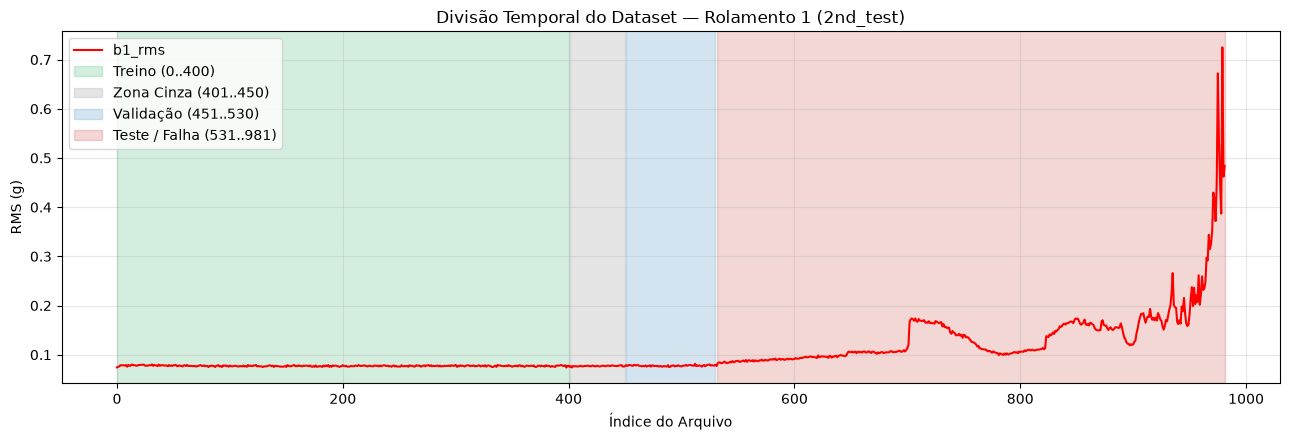

In [15]:
# Visualizando a divisão temporal sobre a curva do RMS
plt.figure(figsize=(13, 4.5))
plt.plot(df_b1["idx"], df_b1["b1_rms"], color="Red", alpha=1, lw=1.5, label="b1_rms")

plt.axvspan(0, 400, color="#27ae60", alpha=0.2, label="Treino (0..400)")
plt.axvspan(401, 450, color="gray", alpha=0.2, label="Zona Cinza (401..450)")
plt.axvspan(451, 530, color="#2980b9", alpha=0.2, label="Validação (451..530)")
plt.axvspan(531, 981, color="#c0392b", alpha=0.2, label="Teste / Falha (531..981)")

plt.title("Divisão Temporal do Dataset — Rolamento 1 (2nd_test)")
plt.xlabel("Índice do Arquivo")
plt.ylabel("RMS (g)")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Padronização (`StandardScaler`) e Salvamento dos Dados Processados
- O `StandardScaler` é ajustado (`fit`) **somente no conjunto de treino** para que nenhuma informação do futuro vaze para o modelo.

In [17]:
pasta_processed = raiz_projeto / "data" / "processed"
pasta_processed.mkdir(parents=True, exist_ok=True)

scaler = StandardScaler()

df_train_scaled = df_train.copy()
df_val_scaled   = df_val.copy()
df_test_scaled  = df_test.copy()

# Ajusta apenas no treino e aplica em treino, validação e teste
df_train_scaled[colunas_b1] = scaler.fit_transform(df_train[colunas_b1])
df_val_scaled[colunas_b1]   = scaler.transform(df_val[colunas_b1])
df_test_scaled[colunas_b1]  = scaler.transform(df_test[colunas_b1])

# Salvando os arquivos para a etapa de modelagem
df_train_scaled.to_csv(pasta_processed / "train" / "train_scaled.csv", index=False)
df_val_scaled.to_csv(pasta_processed / "val" / "val_scaled.csv", index=False)
df_test_scaled.to_csv(pasta_processed / "test" / "test_scaled.csv", index=False)

print("Datasets padronizados e salvos com sucesso em data/processed/:")
print("- train_scaled.csv:", df_train_scaled.shape)
print("- val_scaled.csv:  ", df_val_scaled.shape)
print("- test_scaled.csv: ", df_test_scaled.shape)
display(df_train_scaled.head())

Datasets padronizados e salvos com sucesso em data/processed/:
- train_scaled.csv: (401, 14)
- val_scaled.csv:   (80, 14)
- test_scaled.csv:  (451, 14)


,idx,filename,timestamp,b1_rms,b1_peak,b1_p2p,b1_crest_factor,b1_kurtosis,b1_energy_low,b1_energy_mid,b1_energy_high,b1_energy_bpfo,b1_energy_bpfi,b1_energy_bsf2x
0,0,2004.02.12.10.32.39,2004-02-12 10:32:39,-2.837310,1.259086,1.163529,1.768609,2.082415,4.814565,-0.849934,-4.568921,-0.258267,0.656500,0.415415
1,1,2004.02.12.10.42.39,2004-02-12 10:42:39,-1.715604,-0.409064,-0.167984,-0.172242,2.283965,0.315383,-1.787176,-2.915459,0.618199,0.999566,2.249850
2,2,2004.02.12.10.52.39,2004-02-12 10:52:39,-0.925845,2.497561,2.174196,2.722121,0.892553,0.669310,0.086809,-2.517256,-0.529924,1.508282,0.873591
3,3,2004.02.12.11.02.39,2004-02-12 11:02:39,1.398644,5.151436,6.682092,4.965095,7.544098,-0.303859,1.703800,0.093311,-0.635600,0.055250,0.889910
4,4,2004.02.12.11.12.39,2004-02-12 11:12:39,1.166199,-0.333239,0.233074,-0.500414,1.818349,-0.086009,1.426523,-0.246924,-0.904946,1.295437,2.065315
